In [3]:
import pandas as pd
print(pd.__version__)

3.0.6


In [4]:
import pandas as pd
df = pd.read_csv("../data/demanddata_2022.csv")
df.head()

,SETTLEMENT_DATE,SETTLEMENT_PERIOD,ND,TSD,ENGLAND_WALES_DEMAND,EMBEDDED_WIND_GENERATION,EMBEDDED_WIND_CAPACITY,EMBEDDED_SOLAR_GENERATION,EMBEDDED_SOLAR_CAPACITY,NON_BM_STOR,...,IFA_FLOW,IFA2_FLOW,BRITNED_FLOW,MOYLE_FLOW,EAST_WEST_FLOW,NEMO_FLOW,NSL_FLOW,ELECLINK_FLOW,VIKING_FLOW,GREENLINK_FLOW
0,01-JAN-2022,1,21940,23275,20513,2713,6527,0,14008,0,...,-181,-4,586,320,384,-100,210,0,0,0
1,01-JAN-2022,2,22427,23489,21021,2755,6527,0,14008,0,...,-181,-4,583,320,403,-104,176,0,0,0
2,01-JAN-2022,3,21896,23672,20619,2930,6527,0,14008,0,...,-164,-4,567,320,440,-4,-205,0,0,0
3,01-JAN-2022,4,20693,23272,19615,3090,6527,0,14008,0,...,-170,-4,444,320,387,-6,-283,0,0,0
4,01-JAN-2022,5,19481,23958,18545,3161,6527,0,14008,0,...,-753,-4,-383,320,476,-561,-686,0,0,0


In [5]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 17520 entries, 0 to 17519
Data columns (total 21 columns):
 #   Column                     Non-Null Count  Dtype
---  ------                     --------------  -----
 0   SETTLEMENT_DATE            17520 non-null  str  
 1   SETTLEMENT_PERIOD          17520 non-null  int64
 2   ND                         17520 non-null  int64
 3   TSD                        17520 non-null  int64
 4   ENGLAND_WALES_DEMAND       17520 non-null  int64
 5   EMBEDDED_WIND_GENERATION   17520 non-null  int64
 6   EMBEDDED_WIND_CAPACITY     17520 non-null  int64
 7   EMBEDDED_SOLAR_GENERATION  17520 non-null  int64
 8   EMBEDDED_SOLAR_CAPACITY    17520 non-null  int64
 9   NON_BM_STOR                17520 non-null  int64
 10  PUMP_STORAGE_PUMPING       17520 non-null  int64
 11  IFA_FLOW                   17520 non-null  int64
 12  IFA2_FLOW                  17520 non-null  int64
 13  BRITNED_FLOW               17520 non-null  int64
 14  MOYLE_FLOW                 17520 

In [6]:
#SETTLEMENT_DATE is text so we want to convert it to a real date.
df["date"] = pd.to_datetime(df["SETTLEMENT_DATE"], format = "%d-%b-%Y")
#Period 1 is the first half hour of the day, each period is 30 minutes long
#Doing maths in UTC avoids problems on days where the clock changes
day_start = df["date"].dt.tz_localize("Europe/London").dt.tz_convert("UTC")
df["timestamp_utc"] = day_start + pd.to_timedelta((df["SETTLEMENT_PERIOD"] - 1) * 30, unit="min")

df[["SETTLEMENT_DATE", "SETTLEMENT_PERIOD", "timestamp_utc", "ND"]].head()

,SETTLEMENT_DATE,SETTLEMENT_PERIOD,timestamp_utc,ND
0,01-JAN-2022,1,2022-01-01 00:00:00+00:00,21940
1,01-JAN-2022,2,2022-01-01 00:30:00+00:00,22427
2,01-JAN-2022,3,2022-01-01 01:00:00+00:00,21896
3,01-JAN-2022,4,2022-01-01 01:30:00+00:00,20693
4,01-JAN-2022,5,2022-01-01 02:00:00+00:00,19481


In [7]:
print("Duplicate timestamps:", df["timestamp_utc"].duplicated().sum())
print()
print(df["timestamp_utc"].sort_values().diff().value_counts())
print()
print(df.groupby("date").size().value_counts())

Duplicate timestamps: 0

timestamp_utc
0 days 00:30:00    17519
Name: count, dtype: int64

48    363
46      1
50      1
Name: count, dtype: int64


In [8]:
files = [
    "../data/demanddata_2022.csv",
    "../data/demanddata_2023.csv",
    "../data/demanddata_2024.csv",
]

raw = pd.concat([pd.read_csv(f) for f in files], ignore_index=True)
raw.shape

(52608, 22)

In [9]:
# The yearly files use different date formats (e.g. "01-JAN-2022" vs "01-Jan-23"),
# so let pandas infer the format row by row.
raw["date"] = pd.to_datetime(raw["SETTLEMENT_DATE"], format="mixed", dayfirst=True)

day_start = raw["date"].dt.tz_localize("Europe/London").dt.tz_convert("UTC")
raw["timestamp_utc"] = day_start + pd.to_timedelta((raw["SETTLEMENT_PERIOD"] - 1) * 30, unit="min")

demand = (
    raw[["timestamp_utc", "date", "SETTLEMENT_PERIOD", "ND"]]
    .sort_values("timestamp_utc")
    .set_index("timestamp_utc")
)

demand.head()


,date,SETTLEMENT_PERIOD,ND
timestamp_utc,,,
2022-01-01 00:00:00+00:00,2022-01-01,1,21940
2022-01-01 00:30:00+00:00,2022-01-01,2,22427
2022-01-01 01:00:00+00:00,2022-01-01,3,21896
2022-01-01 01:30:00+00:00,2022-01-01,4,20693
2022-01-01 02:00:00+00:00,2022-01-01,5,19481


In [10]:
print("Rows:", len(demand))
print("Duplicate timestamps:", demand.index.duplicated().sum())
print()
print(demand.index.to_series().diff().value_counts())
print()
print(demand.groupby("date").size().value_counts())

Rows: 52608
Duplicate timestamps: 0

timestamp_utc
0 days 00:30:00    52607
Name: count, dtype: int64

48    1090
46       3
50       3
Name: count, dtype: int64


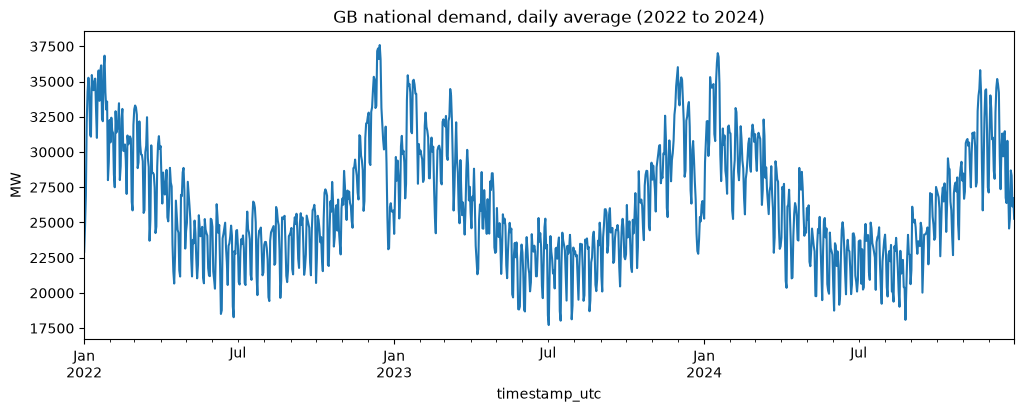

In [11]:
import matplotlib.pyplot as plt

daily = demand["ND"].resample("D").mean()

daily.plot(figsize=(12, 4))
plt.title("GB national demand, daily average (2022 to 2024)")
plt.ylabel("MW")
plt.show()

From 2022 to 2024 demand is highest during the colder winter months of the year then drops as the summer months approach.

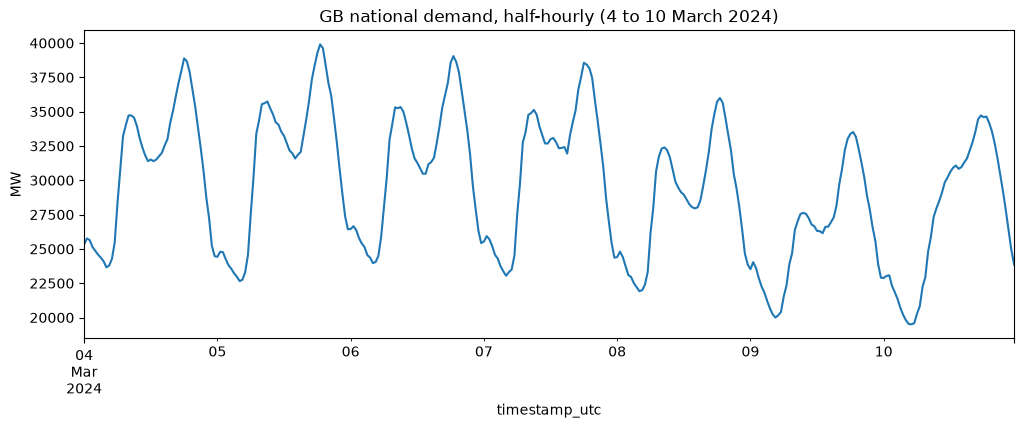

In [12]:
week = demand.loc["2024-03-04":"2024-03-10", "ND"]

week.plot(figsize=(12, 4))
plt.title("GB national demand, half-hourly (4 to 10 March 2024)")
plt.ylabel("MW")
plt.show()

Demand seems to be the same day to day through the week.

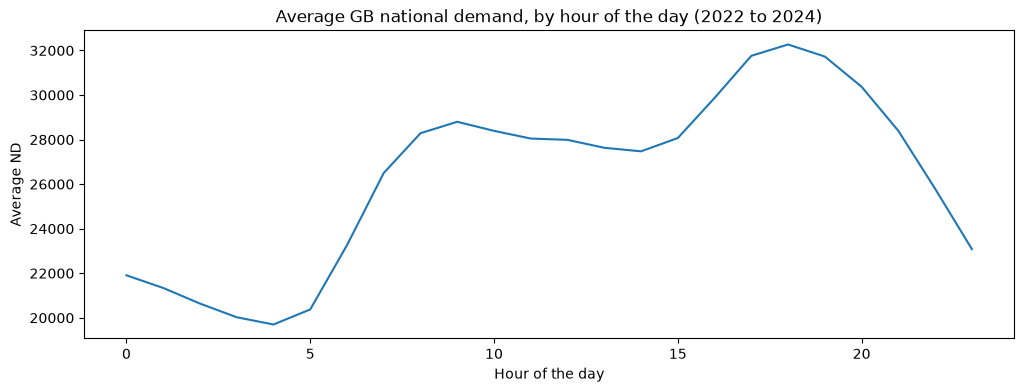

In [13]:
hourly = (demand["ND"].groupby(demand.index.tz_convert("Europe/London").hour).mean()
)

hourly.plot(figsize=(12, 4))
plt.title("Average GB national demand, by hour of the day (2022 to 2024)")
plt.ylabel("Average ND")
plt.xlabel("Hour of the day")
plt.show()

Demand is hugher during the evenings.

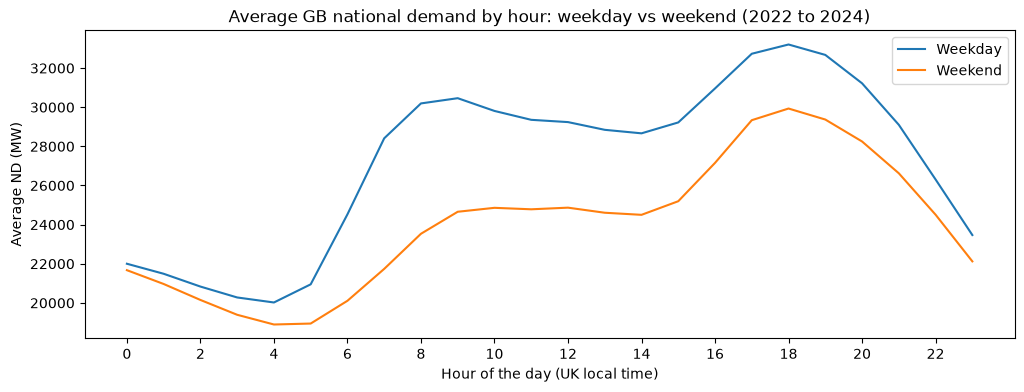

In [14]:
local = demand.index.tz_convert("Europe/London")

is_weekend = local.dayofweek >= 5

by_daytype = (
    demand["ND"]
    .groupby([local.hour, is_weekend])
    .mean()
    .unstack()
)

by_daytype.columns = ["Weekday", "Weekend"]

by_daytype.plot(figsize=(12, 4))
plt.title("Average GB national demand by hour: weekday vs weekend (2022 to 2024)")
plt.xlabel("Hour of the day (UK local time)")
plt.ylabel("Average ND (MW)")
plt.xticks(range(0, 24, 2))
plt.legend()
plt.show()


Demand is higher on weekdays compared to weekends, this could be due to people being out of the house at weekends.

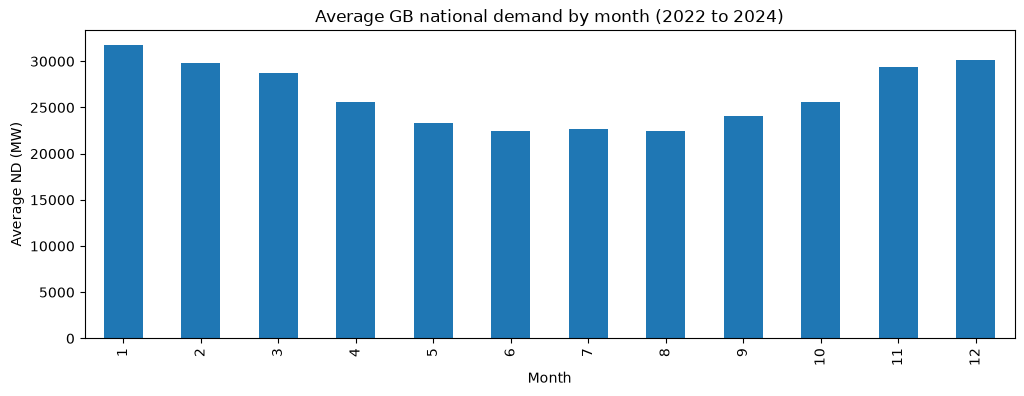

In [15]:
local = demand.index.tz_convert("Europe/London")

by_month = demand["ND"].groupby([local.month]).mean()
by_month.plot(kind = "bar", figsize=(12, 4))
plt.title("Average GB national demand by month (2022 to 2024)")
plt.xlabel("Month")
plt.ylabel("Average ND (MW)")
plt.show()

Demand Peaks around December - January time and slows mid year in the summer, this is probably due to warmer weather in the summer months.

In [16]:
local = demand.index.tz_convert("Europe/London")
features = pd.DataFrame(index=demand.index)
features["half_hour"] = local.hour * 2 + local.minute // 30
features["dayofweek"] = local.dayofweek
features["month"] = local.month

features.head()

,half_hour,dayofweek,month
timestamp_utc,,,
2022-01-01 00:00:00+00:00,0,5,1
2022-01-01 00:30:00+00:00,1,5,1
2022-01-01 01:00:00+00:00,2,5,1
2022-01-01 01:30:00+00:00,3,5,1
2022-01-01 02:00:00+00:00,4,5,1


Creates table documenting every day, 2022 through to 2024 and splits it into half hours.

In [17]:
import holidays

local = demand.index.tz_convert("Europe/London")

uk_holidays = holidays.country_holidays("GB", subdiv="ENG", years=[2022, 2023, 2024])

features["bank_holiday"] = (
    pd.Series(local.date, index=demand.index)
    .isin(list(uk_holidays.keys()))
    .astype(int)
)

features.head()

,half_hour,dayofweek,month,bank_holiday
timestamp_utc,,,,
2022-01-01 00:00:00+00:00,0,5,1,1
2022-01-01 00:30:00+00:00,1,5,1,1
2022-01-01 01:00:00+00:00,2,5,1,1
2022-01-01 01:30:00+00:00,3,5,1,1
2022-01-01 02:00:00+00:00,4,5,1,1


Imports a library that contains all of the bank holiday dates of the uk through the last few years, then marks each day which is a bank holiday with a 1.

In [18]:
features["Yesterday"] = demand["ND"].shift(48)
features["Last_week"] = demand["ND"].shift(48 * 7)
features.describe()

,half_hour,dayofweek,month,bank_holiday,Yesterday,Last_week
count,52608.000000,52608.000000,52608.000000,52608.000000,52560.000000,52272.000000
mean,23.500000,3.000000,6.522696,0.027372,26321.202702,26319.551098
std,13.853531,2.002299,3.449014,0.163167,6035.039356,6040.334925
min,0.000000,0.000000,1.000000,0.000000,13601.000000,13601.000000
25%,11.750000,1.000000,4.000000,0.000000,21606.000000,21602.000000
50%,23.500000,3.000000,7.000000,0.000000,25520.500000,25516.000000
75%,35.250000,5.000000,10.000000,0.000000,30120.250000,30114.000000
max,47.000000,6.000000,12.000000,1.000000,46147.000000,46147.000000


Adds two more columns to the table that has been created, one column shows the energy used for this time last week and the other column shows the energy used for the same time yesterday. The head shows these columns to be NaN because we have not downloaded data from 2021 only 2022 - 2024.

In [19]:

print(features.columns.tolist())
print(features.isna().sum())

['half_hour', 'dayofweek', 'month', 'bank_holiday', 'Yesterday', 'Last_week']
half_hour         0
dayofweek         0
month             0
bank_holiday      0
Yesterday        48
Last_week       336
dtype: int64


Checks that the table we have created is correct. 

In [20]:
data = features.join(demand["ND"]).dropna()





Creates a new table called data which adds ND as a column 

In [21]:
train = data.loc["2022-01-01 00:00:00":"2023-12-31 23:59:59"]
test = data.loc["2024-01-01 00:00:00":"2024-12-31 23:59:59"]

x_train = train.drop(columns=["ND"])
y_train = train["ND"]
x_test = test.drop(columns=["ND"])
y_test = test["ND"] 

Here I have created 4 objects, the x objects hold the 6 columns from data we collected earlier and the y objects hold the ND. I have split these objects between the train data for years 2022, 2023 to the test data for years 2024. What I am doing here is preparing the data for years 2022, 2023 to help predict what the future ND will be and I will use 2024 as a benchmark to see how accurate these tests are.

In [22]:
import sklearn as sk

baseline_prediction = x_test["Last_week"]
baseline_MAE = sk.metrics.mean_absolute_error(y_test, baseline_prediction)
baseline_RMSE = sk.metrics.root_mean_squared_error(y_test, baseline_prediction)
print(baseline_MAE)
print(baseline_RMSE)
print(y_test.mean())
MAE_percentage = (baseline_MAE /y_test.mean() * 100).round(2)
print("The errors in the dataset are about", MAE_percentage,"% of the average demand")

2027.9001024590164
2686.538444696779
26286.762978142076
The errors in the dataset are about 7.71 % of the average demand



Before building any models, I need a simple benchmark to beat. The baseline predicts that demand at any half-hour will equal demand at the same half-hour one week earlier (the `Last_week` feature). It involves no training, so it shows what a trivial forecast achieves on the 2024 test set

In [24]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, root_mean_squared_error

cat_cols = ["half_hour", "dayofweek", "month"]

# Turn the category-like numbers into separate yes/no columns
X_train_lin = pd.get_dummies(x_train, columns=cat_cols, dtype=float)
X_test_lin = pd.get_dummies(x_test, columns=cat_cols, dtype=float)

# Make sure both tables have exactly the same columns in the same order
X_test_lin = X_test_lin.reindex(columns=X_train_lin.columns, fill_value=0)
print("Columns match:", X_train_lin.columns.equals(X_test_lin.columns))

# Fit on the training data, predict the test data
lin_model = LinearRegression()
lin_model.fit(X_train_lin, y_train)
lin_pred = lin_model.predict(X_test_lin)

lin_mae = mean_absolute_error(y_test, lin_pred)
lin_rmse = root_mean_squared_error(y_test, lin_pred)

print(f"Baseline MAE:           {baseline_MAE:,.0f} MW")
print(f"Linear regression MAE:  {lin_mae:,.0f} MW")
print(f"Baseline RMSE:          {baseline_RMSE:,.0f} MW")
print(f"Linear regression RMSE: {lin_rmse:,.0f} MW")

Columns match: True
Baseline MAE:           2,028 MW
Linear regression MAE:  1,399 MW
Baseline RMSE:          2,687 MW
Linear regression RMSE: 1,827 MW


Model 1: Linear Regression
This first model is linear regression it learns one weight for each input column and combines them into a forecast 
The model was fitted on the training data which is years 2022 and 2023 and scored on year 2024


In [27]:
from sklearn.ensemble import HistGradientBoostingRegressor

gb_model = HistGradientBoostingRegressor(
    max_iter=300,
    early_stopping=False,
    random_state=0,
)
gb_model.fit(x_train, y_train)
gb_pred = gb_model.predict(x_test)

gb_mae = mean_absolute_error(y_test, gb_pred)
gb_rmse = root_mean_squared_error(y_test, gb_pred)

print(f"Baseline MAE:           {baseline_MAE:,.0f} MW")
print(f"Linear regression MAE:  {lin_mae:,.0f} MW")
print(f"Gradient boosting MAE:  {gb_mae:,.0f} MW")
print()
print(f"Baseline RMSE:          {baseline_RMSE:,.0f} MW")
print(f"Linear regression RMSE: {lin_rmse:,.0f} MW")
print(f"Gradient boosting RMSE: {gb_rmse:,.0f} MW")

Baseline MAE:           2,028 MW
Linear regression MAE:  1,399 MW
Gradient boosting MAE:  1,249 MW

Baseline RMSE:          2,687 MW
Linear regression RMSE: 1,827 MW
Gradient boosting RMSE: 1,676 MW


This model is gradient boosting, it builds small decision trees that each correct the errors of the previous ones so that it can capture interactions that a linear model cannot. For example one of these interactions may be the evening peak that is different in the winter compared to the summer.
I switched off early stoppage because scikitlearn default holds back a random slice of the training data which would leak future information in a time series.